# Scenarios 1 and 2: training curves and client selection, 5 methods x 3 seeds

Random vs Wen et al. (fresh F3) vs Wen et al. + GPU vs Polaris vs Ours (GPU estimator), seeds 4126 / 4127 / 4128.

| label | S1 cell | what it is |
|---|---|---|
| Random | `S1_random` | uniform random selection |
| Wen et al. (fresh F3) | `S1_wen_fresh` | Wen-faithful selector, F3 re-evaluated with the current global model at every merge |
| Wen et al. + GPU | `S1_wen_fresh_gpu` | the same selector, F1/F2 from the GPU estimator instead of the CPU model |
| Polaris | `S1_polaris` | Polaris host (Kang & Li), ADR-0020 |
| Ours | `S1_gpu` | GPU estimator, egreedy eps = 0.2 |

Run directories follow `wen_ptable.run_dir` (seed 4126 is read from `runs/wen_env/_phaseA/` when it is there),
so the numbers match `evidence/s1_final.md` and `evidence/s2_final.md`.
Kernel: **Python (plato .venv)**.

* Fig. 1 - accuracy vs simulated time and vs round, up to TTA@85 % (one seed: `SEED`; then all 3 seeds)
* Fig. 2 - TTA at 80 / 85 / 90 % (mean over seeds, one dot per seed)
* Fig. 3 - tier share of dispatches per method (+ the fleet)
* Fig. 4 - tier share per accuracy phase (0-80 / 80-85 / 85-90 %)
* Fig. 5 - where the time goes, distance to the RSU at upload, per-vehicle concentration
* Tables - per seed and mean ± sd over seeds

Every statistic is computed from the dispatch log up to the run's TTA@90 % round; a run that never reaches 90 %
(both Wen arms in S1) contributes its whole 4,000-round run. Fig. 3-5 pool the three seeds (each seed keeps its own
phase boundaries); pass `data_s1[SEED]` instead of `pool(data_s1)` for one seed.

**Reading B:** `S1_gpu` at seed 4126 hung at r1957 when the disk filled; its 89.75 % maximum counts as 90 %
(first reached at round 1950), as in every table since Prompt F (`wen_faithful_v1_step6_footnote.md`).

**Scenario 2** (bottom of the notebook) repeats everything for the same five selectors. `S2_STAGE0` chooses
between all five with Stage 0 (default) and the `s2_final.md` main table (only Ours with Stage 0); a last section
compares each selector with and without Stage 0.

Set `SAVE = True` to write PNG + PDF to `FIG_DIR` / `FIG_DIR_S2`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate examples/async/fedasync no matter where the notebook is opened from.
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs" / "wen_env").is_dir())
RUNS_DIR = BASE / "runs" / "wen_env"

SEEDS = (4126, 4127, 4128)
SEED = 4126                              # seed shown in the single-seed curves and tables

# label -> (cell, colour); the run directory is run_dir(cell, seed)
METHODS = {
    "Random": ("S1_random", "#1baf7a"),
    "Wen et al. (fresh F3)": ("S1_wen_fresh", "#eda100"),
    "Wen et al. + GPU": ("S1_wen_fresh_gpu", "#8c5a14"),
    "Polaris": ("S1_polaris", "#d6336c"),
    "Ours": ("S1_gpu", "#2a78d6"),
}
# (cell, seed) -> accuracy that counts as 90 % for that run (Reading B)
TARGET_OVERRIDE = {("S1_gpu", 4126): 0.8975}
LEVELS = (0.80, 0.85, 0.90)
CURVE_LEVELS = (0.85,)                   # levels marked on the training curves (Fig. 1)
CURVE_STOP = 0.85                        # curves end at TTA@85 % (whole run if never reached)
TIERS = ["xavier", "orin", "thor"]       # slowest -> fastest GPU
TIER_LABEL = {"xavier": "Xavier", "orin": "Orin", "thor": "Thor"}
TIER_COLOR = {"xavier": "#c9c2f2", "orin": "#8a7ce6", "thor": "#4231a8"}  # one hue, light -> dark
FLEET = {"xavier": 15, "orin": 10, "thor": 5}                           # n30_x15-o10-t5
VEHICLES = [f"veh{i:02d}" for i in range(30)]
SEED_LS = {4126: "-", 4127: "--", 4128: ":"}

SAVE = False
FIG_DIR = BASE / "wen_env" / "evidence" / "figs_s1"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

def save(fig, name, fig_dir=FIG_DIR):
    if SAVE:
        fig_dir.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "pdf"):
            fig.savefig(fig_dir / f"{name}.{ext}", bbox_inches="tight")

In [2]:
def run_dir(cell, seed):
    """Same lookup as wen_ptable.run_dir: seed 4126 lives under _phaseA/ when it is there."""
    p = RUNS_DIR / "_phaseA" / f"{cell}_s{seed}"
    return p if seed == 4126 and p.exists() else RUNS_DIR / f"{cell}_s{seed}"


def load(label, seed, methods=METHODS):
    cell, _ = methods[label]
    d = run_dir(cell, seed)
    res = pd.read_csv(next((d / "results").glob("*.csv")))
    dl = pd.read_csv(d / "dispatch_log.csv")
    # TTA at each level = first evaluated round at or above it
    tta = {}
    for lv in LEVELS:
        thr = TARGET_OVERRIDE.get((cell, seed), lv) if lv == 0.90 else lv
        hit = res[res["accuracy"] >= thr - 1e-12]
        tta[lv] = (float(hit["elapsed_time"].iloc[0]), int(hit["round"].iloc[0])) if len(hit) else None
    # energy to each level = E_train + E_up of every dispatch finished by then (lost uploads included)
    e = dl["E_train"] + dl["E_up"]
    energy = {lv: (e[dl["t_finish_clean"] <= t[0]].sum() / 1000 if t else None) for lv, t in tta.items()}
    max_acc = float(res["accuracy"].max())
    last = tta[0.90][1] if tta[0.90] else int(res["round"].max())
    res = res[res["round"] <= last]
    dl = dl[dl["round"] <= last].copy()
    # accuracy phase each dispatch belongs to
    edges = [0] + [tta[lv][1] if tta[lv] else last for lv in LEVELS]
    edges = sorted(set(edges))
    names = ["0-80%", "80-85%", "85-90%"][: len(edges) - 1]
    dl["phase"] = pd.cut(dl["round"], edges, labels=names, include_lowest=True).astype(str)
    dl["seed"] = seed
    return {"res": res, "dl": dl, "tta": tta, "energy": energy, "max_acc": max_acc, "last": last,
            "run": d}


def load_all(methods=METHODS, seeds=SEEDS):
    """seed -> label -> run"""
    return {s: {m: load(m, s, methods) for m in methods} for s in seeds}


def pool(data_by_seed):
    """label -> the dispatch logs of all seeds stacked (each seed keeps its own phases)."""
    labels = next(iter(data_by_seed.values()))
    return {m: {"dl": pd.concat([d[m]["dl"] for d in data_by_seed.values()], ignore_index=True)}
            for m in labels}


def report(data_by_seed):
    for s, data in data_by_seed.items():
        for m, v in data.items():
            print(f"s{s}  {m:34s} rounds used {v['last']:5d}  dispatches {len(v['dl']):5d}  TTA:",
                  {f"{lv:.0%}": (f"{t[0]:.0f}s r{t[1]}" if t else "not reached")
                   for lv, t in v["tta"].items()})

data_s1 = load_all()
report(data_s1)

s4126  Random                             rounds used  1770  dispatches  1772  TTA: {'80%': '1419s r380', '85%': '2568s r680', '90%': '6645s r1770'}
s4126  Wen et al. (fresh F3)              rounds used  4000  dispatches  4002  TTA: {'80%': '1967s r560', '85%': '7263s r2100', '90%': 'not reached'}
s4126  Wen et al. + GPU                   rounds used  4000  dispatches  4002  TTA: {'80%': '1675s r570', '85%': '5046s r1710', '90%': 'not reached'}
s4126  Polaris                            rounds used  2020  dispatches  2022  TTA: {'80%': '1580s r420', '85%': '2452s r650', '90%': '7646s r2020'}
s4126  Ours                               rounds used  1950  dispatches  1952  TTA: {'80%': '1158s r390', '85%': '2089s r680', '90%': '6326s r1950'}
s4127  Random                             rounds used  2040  dispatches  2042  TTA: {'80%': '1678s r450', '85%': '3177s r840', '90%': '7749s r2040'}
s4127  Wen et al. (fresh F3)              rounds used  4000  dispatches  4002  TTA: {'80%': '1839s r510'

## Fig. 1 - Training curves

The server evaluates every 10 rounds, so only evaluation rounds are plotted. Each curve stops at the
run's TTA@85 % round (`CURVE_STOP`); a run that never reaches 85 % is plotted to its last round (4,000). The dashed line and dots mark
85 % only (`CURVE_LEVELS`): each dot is the first time a run reaches it. First one seed (`SEED`), then all three seeds overlaid.

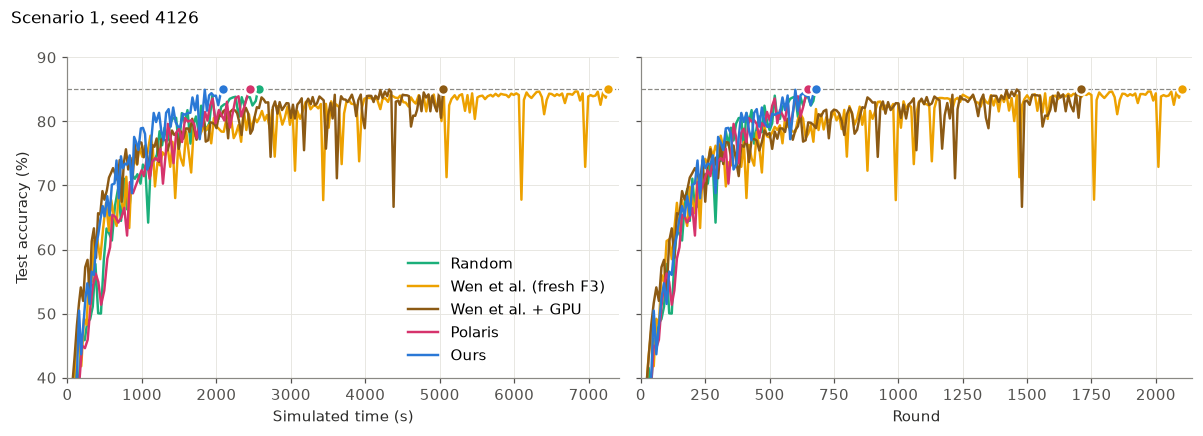

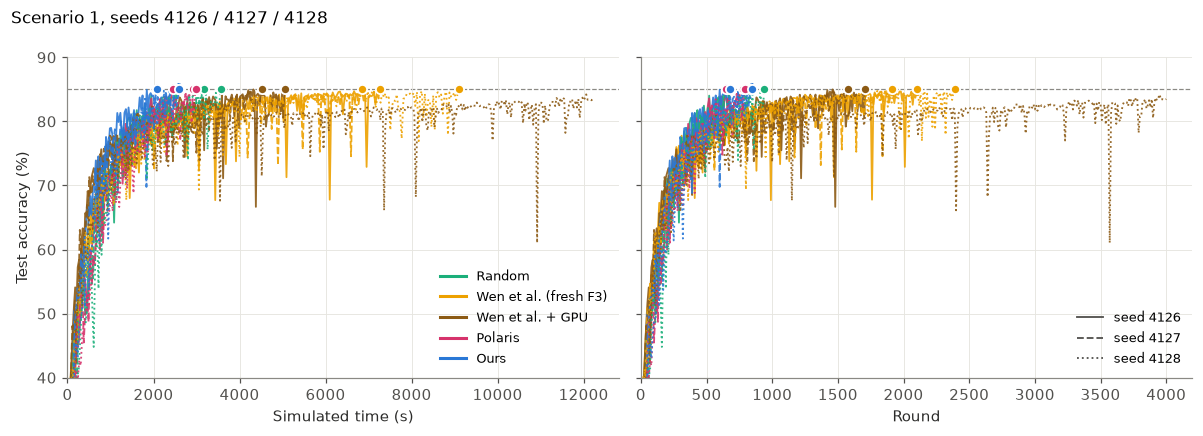

In [3]:
def curve_res(v):
    """Evaluated rounds up to the run's TTA@CURVE_STOP round (whole run if it never gets there)."""
    r = v["res"]
    t = v["tta"][CURVE_STOP]
    if t:
        r = r[r["round"] <= t[1]]
    return r[(r["round"] % 10 == 0) | (r["round"] == r["round"].max())]


def plot_curves(data, methods, title, name, fig_dir=FIG_DIR, xmax=None, note=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, xkey, xlabel in [(axes[0], "elapsed_time", "Simulated time (s)"), (axes[1], "round", "Round")]:
        for m, v in data.items():
            col = methods[m][1]
            r = curve_res(v)
            ax.plot(r[xkey], r["accuracy"] * 100, color=col, lw=1.6, label=m)
            for lv in CURVE_LEVELS:
                t = v["tta"][lv]
                if t:
                    ax.plot(t[0] if xkey == "elapsed_time" else t[1], lv * 100, "o", ms=7,
                            color=col, mec="white", mew=1.5, zorder=5)
        for lv in CURVE_LEVELS:
            ax.axhline(lv * 100, color="#8a8984", lw=0.8, ls="--", zorder=0)
        ax.set_xlabel(xlabel)
        ax.set_ylim(40, 90)
    axes[0].set_ylabel("Test accuracy (%)")
    axes[0].legend(loc="lower right")
    xmax = xmax or (max(curve_res(v)["elapsed_time"].max() for v in data.values()) * 1.02,
                    max(curve_res(v)["round"].max() for v in data.values()) * 1.02)
    axes[0].set_xlim(0, xmax[0])
    axes[1].set_xlim(0, xmax[1])
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    if note:
        fig.text(0.01, -0.02, note, fontsize=8, color="#52514e")
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()


def plot_curves_seeds(data_by_seed, methods, title, name, fig_dir=FIG_DIR, note=None):
    """All seeds overlaid: colour = method, line style = seed; dots = TTA at CURVE_LEVELS."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, xkey, xlabel in [(axes[0], "elapsed_time", "Simulated time (s)"), (axes[1], "round", "Round")]:
        for s, data in data_by_seed.items():
            for m, v in data.items():
                col = methods[m][1]
                r = curve_res(v)
                ax.plot(r[xkey], r["accuracy"] * 100, color=col, lw=1.2, ls=SEED_LS[s], alpha=0.9)
                for lv in CURVE_LEVELS:
                    t = v["tta"][lv]
                    if t:
                        ax.plot(t[0] if xkey == "elapsed_time" else t[1], lv * 100, "o", ms=6,
                                color=col, mec="white", mew=1.2, zorder=5)
        for lv in CURVE_LEVELS:
            ax.axhline(lv * 100, color="#8a8984", lw=0.8, ls="--", zorder=0)
        ax.set_xlabel(xlabel)
        ax.set_ylim(40, 90)
        ax.set_xlim(0, None)
    axes[0].set_ylabel("Test accuracy (%)")
    labels = next(iter(data_by_seed.values()))
    h_m = [plt.Line2D([], [], color=methods[m][1], lw=2) for m in labels]
    h_s = [plt.Line2D([], [], color="#52514e", lw=1.2, ls=SEED_LS[s]) for s in data_by_seed]
    axes[0].legend(h_m, list(labels), loc="lower right", fontsize=8.5)
    axes[1].legend(h_s, [f"seed {s}" for s in data_by_seed], loc="lower right", fontsize=8.5)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    if note:
        fig.text(0.01, -0.02, note, fontsize=8, color="#52514e")
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()


plot_curves(data_s1[SEED], METHODS, f"Scenario 1, seed {SEED}", f"s1_training_curves_s{SEED}",
)
plot_curves_seeds(data_s1, METHODS, "Scenario 1, seeds 4126 / 4127 / 4128", "s1_training_curves_3seeds")

## Fig. 2 - Time to accuracy

Bar = mean over the seeds that reached the level, dots = individual seeds. A hatched bar means some seeds
never reached that level (the label says how many did); "not reached" means none did.

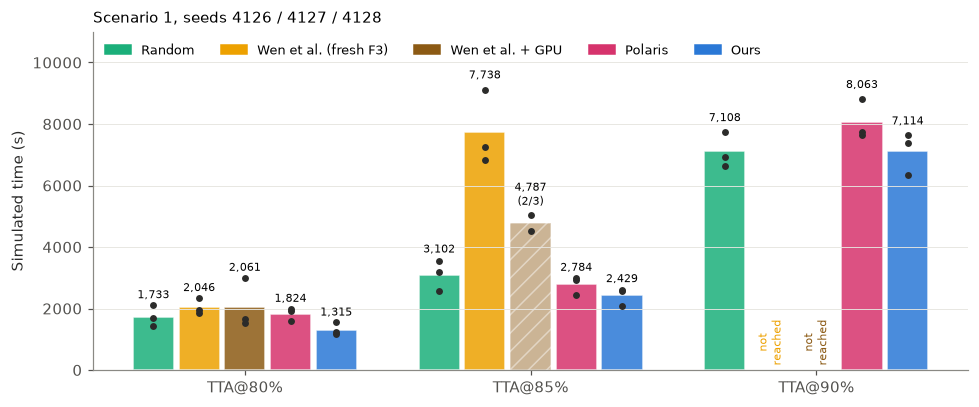

In [4]:
def plot_tta(data_by_seed, methods, title, name, fig_dir=FIG_DIR):
    labels = list(next(iter(data_by_seed.values())))
    n_seeds = len(data_by_seed)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    w = 0.8 / len(labels)
    for j, m in enumerate(labels):
        col = methods[m][1]
        for i, lv in enumerate(LEVELS):
            x = i + (j - (len(labels) - 1) / 2) * w
            ts = [d[m]["tta"][lv][0] for d in data_by_seed.values() if d[m]["tta"][lv]]
            if not ts:
                ax.text(x, 150, "not\nreached", ha="center", va="bottom", fontsize=7.5, color=col,
                        rotation=90)
                continue
            partial = len(ts) < n_seeds
            ax.bar(x, np.mean(ts), width=w * 0.9, color=col, alpha=0.45 if partial else 0.85,
                   hatch="//" if partial else None, edgecolor="white", linewidth=1)
            ax.plot([x] * len(ts), ts, "o", ms=3.5, color="#2b2b2a", zorder=5)
            lab = f"{np.mean(ts):,.0f}" + (f"\n({len(ts)}/{n_seeds})" if partial else "")
            ax.text(x, max(ts) * 1.02 + 100, lab, ha="center", va="bottom", fontsize=7.5)
    h = [plt.Rectangle((0, 0), 1, 1, color=methods[m][1]) for m in labels]
    ax.legend(h, labels, ncol=len(labels), loc="upper left", fontsize=8.5)
    ax.set_xticks(range(len(LEVELS)), [f"TTA@{lv:.0%}" for lv in LEVELS])
    ax.set_ylabel("Simulated time (s)")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=10)
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()


plot_tta(data_s1, METHODS, "Scenario 1, seeds 4126 / 4127 / 4128", "s1_tta_3seeds")

## Fig. 3 - Which vehicle types each method dispatches

Share of dispatches per GPU tier up to TTA@90 % (Wen: whole run), three seeds pooled. The top bar is the fleet
itself (15 Xavier / 10 Orin / 5 Thor): a method that picks uniformly at random matches it.

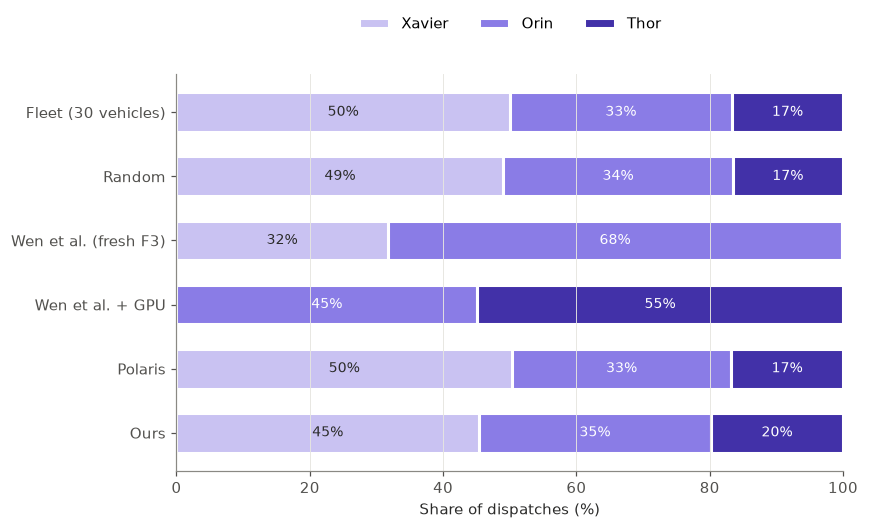

,xavier,orin,thor
Fleet (30 vehicles),50.0,33.3,16.7
Random,49.0,34.4,16.6
Wen et al. (fresh F3),31.7,68.2,0.1
Wen et al. + GPU,0.0,45.1,54.9
Polaris,50.3,32.9,16.8
Ours,45.4,34.8,19.8


In [5]:
def tier_share(df):
    return df["tier"].value_counts(normalize=True).reindex(TIERS, fill_value=0) * 100


def plot_tier_share(data, name, fig_dir=FIG_DIR):
    rows = {"Fleet (30 vehicles)": pd.Series(FLEET).reindex(TIERS) / sum(FLEET.values()) * 100}
    rows.update({m: tier_share(v["dl"]) for m, v in data.items()})
    share = pd.DataFrame(rows).T

    fig, ax = plt.subplots(figsize=(8, 0.75 * len(data) + 1.2))
    y = np.arange(len(share))[::-1]
    left = np.zeros(len(share))
    for t in TIERS:
        ax.barh(y, share[t], left=left, color=TIER_COLOR[t], edgecolor="white", linewidth=2,
                height=0.62, label=TIER_LABEL[t])
        for yi, l, w in zip(y, left, share[t]):
            if w >= 4:
                ax.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                        color="white" if t != "xavier" else "#2b2b2a")
        left += share[t].values
    ax.set_yticks(y, share.index)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Share of dispatches (%)")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()
    return share.round(1)


plot_tier_share(pool(data_s1), "s1_tier_share_3seeds")

## Fig. 4 - Tier share per accuracy phase

Phase boundaries are each run's own TTA@80 % and TTA@85 % rounds; the three seeds are pooled.

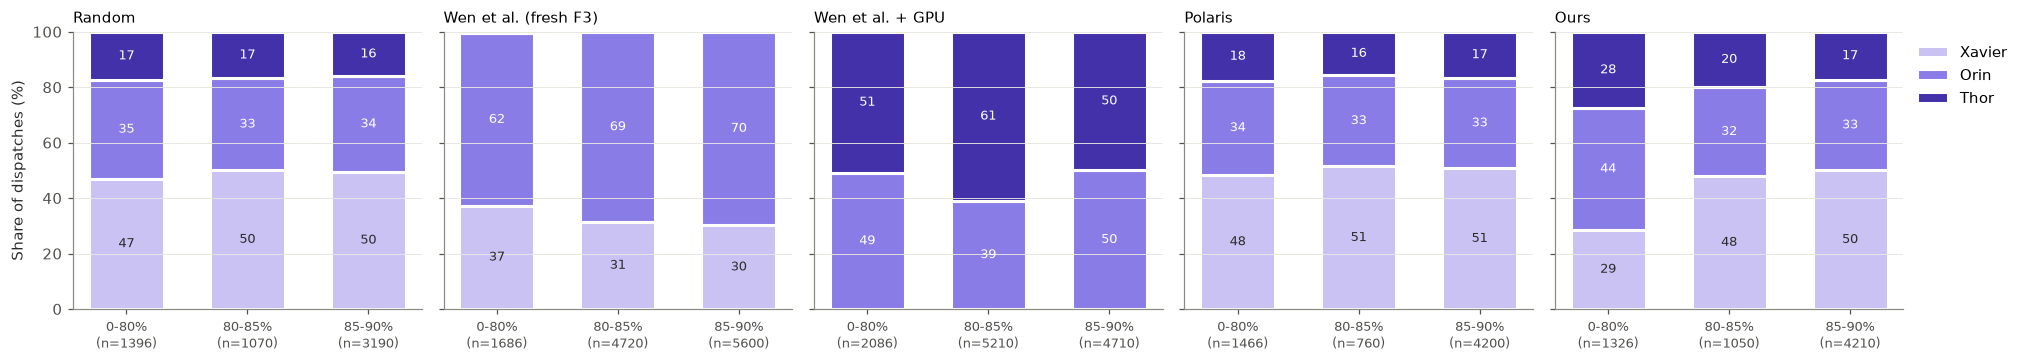

In [6]:
def plot_tier_share_by_phase(data, name, fig_dir=FIG_DIR):
    fig, axes = plt.subplots(1, len(data), figsize=(3.7 * len(data), 3.4), sharey=True)
    for ax, (m, v) in zip(axes, data.items()):
        ph = (v["dl"].groupby("phase")["tier"].value_counts(normalize=True)
              .unstack().reindex(columns=TIERS, fill_value=0).fillna(0) * 100)
        x = np.arange(len(ph))
        bottom = np.zeros(len(ph))
        for t in TIERS:
            ax.bar(x, ph[t], bottom=bottom, color=TIER_COLOR[t], edgecolor="white", linewidth=2,
                   width=0.62, label=TIER_LABEL[t])
            for xi, b, h in zip(x, bottom, ph[t]):
                if h >= 6:
                    ax.text(xi, b + h / 2, f"{h:.0f}", ha="center", va="center", fontsize=8.5,
                            color="white" if t != "xavier" else "#2b2b2a")
            bottom += ph[t].values
        n = v["dl"].groupby("phase").size()
        ax.set_xticks(x, [f"{p}\n(n={n[p]})" for p in ph.index], fontsize=8.5)
        ax.set_title(m, fontsize=10, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Share of dispatches (%)")
    axes[0].set_ylim(0, 100)
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()

plot_tier_share_by_phase(pool(data_s1), "s1_tier_share_by_phase_3seeds")

## Fig. 5 - Why Ours is faster per round

With C = 3 vehicles in flight, seconds per round ≈ mean dispatch duration / 3, and a dispatch's
duration is training time plus upload time. (a) splits the mean duration into these two parts.
(b) shows the vehicle's distance to the RSU when it starts uploading, which sets the upload rate.
(c) shows how evenly each method spreads its dispatches over the 30 vehicles, which affects how many
rounds the model needs (sorted per seed, then averaged over seeds).

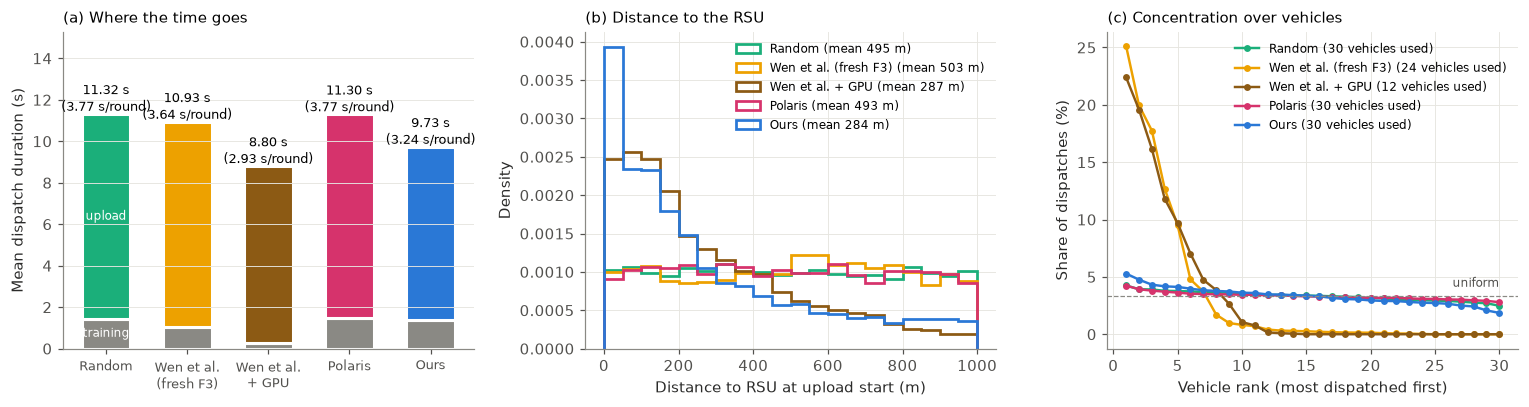

In [7]:
def plot_why(data, methods, name, fig_dir=FIG_DIR):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

    # (a) mean duration = training + upload
    ax = axes[0]
    names = list(data)
    tr = [data[m]["dl"]["T_train_true"].mean() for m in names]
    up = [data[m]["dl"]["T_up_true"].mean() for m in names]
    x = np.arange(len(names))
    ax.bar(x, tr, color="#8a8984", width=0.6, edgecolor="white", linewidth=2, label="Training")
    ax.bar(x, up, bottom=tr, color=[methods[m][1] for m in names], width=0.6, edgecolor="white",
           linewidth=2, label="Upload")
    for xi, a, b in zip(x, tr, up):
        ax.text(xi, a + b + 0.15, f"{a + b:.2f} s\n({(a + b) / 3:.2f} s/round)", ha="center", fontsize=8.5)
    ax.set_xticks(x, [n.replace(" (", "\n(").replace(" + ", "\n+ ") for n in names], fontsize=8.5)
    ax.set_ylabel("Mean dispatch duration (s)")
    ax.set_ylim(0, max(a + b for a, b in zip(tr, up)) * 1.35)
    ax.set_title("(a) Where the time goes", loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.text(x[0], tr[0] / 2, "training", ha="center", va="center", fontsize=8, color="white")
    ax.text(x[0], tr[0] + up[0] / 2, "upload", ha="center", va="center", fontsize=8, color="white")

    # (b) distance to RSU at training finish (= start of upload)
    ax = axes[1]
    bins = np.linspace(0, 1000, 21)
    for m in names:
        d = data[m]["dl"]["d_finish"]
        ax.hist(d, bins=bins, histtype="step", lw=1.8, color=methods[m][1], density=True,
                label=f"{m} (mean {d.mean():.0f} m)")
    ax.set_xlabel("Distance to RSU at upload start (m)")
    ax.set_ylabel("Density")
    ax.set_title("(b) Distance to the RSU", loc="left", fontsize=10)
    ax.legend(fontsize=8)

    # (c) per-vehicle share of dispatches, sorted within each seed, then averaged over seeds
    ax = axes[2]
    for m in names:
        per, used = [], []
        for _, g in data[m]["dl"].groupby("seed"):
            c = g["veh_id"].value_counts().reindex(VEHICLES, fill_value=0)
            per.append(np.sort(c.values)[::-1] / c.sum() * 100)
            used.append((c > 0).sum())
        ax.plot(np.arange(1, 31), np.mean(per, axis=0), "-o", ms=3.5, lw=1.6, color=methods[m][1],
                label=f"{m} ({np.mean(used):.0f} vehicles used)")
    ax.axhline(100 / 30, color="#8a8984", lw=0.8, ls="--")
    ax.text(30, 100 / 30 + 0.8, "uniform", ha="right", fontsize=8, color="#52514e")
    ax.set_xlabel("Vehicle rank (most dispatched first)")
    ax.set_ylabel("Share of dispatches (%)")
    ax.set_title("(c) Concentration over vehicles", loc="left", fontsize=10)
    ax.legend(fontsize=8)

    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()

plot_why(pool(data_s1), METHODS, "s1_why_ours_faster_3seeds")

## Tables - numbers behind the figures

`summary_table` is one seed (`SEED`). `seeds_table` is mean ± sd over the three seeds; a level some seeds
never reached shows how many did and the mean of those that did. `per_seed_table` has one row per run.

In [8]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


def run_metrics(v):
    """Numeric metrics of one run (None = level not reached)."""
    dl = v["dl"]
    c = dl["veh_id"].value_counts().reindex(VEHICLES, fill_value=0)
    share = tier_share(dl)
    row = {}
    for lv, t in v["tta"].items():
        row[f"TTA@{lv:.0%} (s)"] = t[0] if t else None
    for lv, t in v["tta"].items():
        row[f"rounds to {lv:.0%}"] = t[1] if t else None
    for lv, e in v["energy"].items():
        row[f"energy to {lv:.0%} (kJ)"] = e
    row.update({
        "max accuracy": v["max_acc"],
        "rounds used": v["last"],
        "s / round": dl["t_finish_clean"].max() / v["last"],
        "mean duration (s)": dl["duration"].mean(),
        "  training (s)": dl["T_train_true"].mean(),
        "  upload (s)": dl["T_up_true"].mean(),
        "distance to RSU at upload (m)": dl["d_finish"].mean(),
        "Xavier (%)": share["xavier"], "Orin (%)": share["orin"], "Thor (%)": share["thor"],
        "vehicles used": int((c > 0).sum()),
        "Gini of per-vehicle dispatches": gini(c),
        "top-5 vehicles' share (%)": c.nlargest(5).sum() / c.sum() * 100,
    })
    return row


FMT = {"max accuracy": "{:.4f}", "Gini of per-vehicle dispatches": "{:.3f}", "s / round": "{:.2f}",
       "mean duration (s)": "{:.2f}", "  training (s)": "{:.2f}", "  upload (s)": "{:.2f}"}


def fmt(k, x):
    f = FMT.get(k, "{:.1f}" if ("kJ" in k or "(%)" in k) else "{:,.0f}")
    return f.format(x)


def summary_table(data):
    """One seed: label -> formatted column."""
    out = {}
    for m, v in data.items():
        out[m] = {k: (fmt(k, x) if x is not None else "not reached") for k, x in run_metrics(v).items()}
    return pd.DataFrame(out)


def seeds_table(data_by_seed):
    """Mean ± sd over seeds: label -> formatted column."""
    labels = next(iter(data_by_seed.values()))
    n = len(data_by_seed)
    out = {}
    for m in labels:
        rows = [run_metrics(d[m]) for d in data_by_seed.values()]
        col = {}
        for k in rows[0]:
            xs = [r[k] for r in rows if r[k] is not None]
            if not xs:
                col[k] = "not reached"
                continue
            s = fmt(k, np.mean(xs)) + (f" ± {fmt(k, np.std(xs, ddof=1))}" if len(xs) > 1 else "")
            col[k] = s if len(xs) == n else f"{s} ({len(xs)}/{n} reached)"
        out[m] = col
    return pd.DataFrame(out)


def per_seed_table(data_by_seed):
    rows = {(m, s): run_metrics(v) for s, d in data_by_seed.items() for m, v in d.items()}
    t = pd.DataFrame(rows).T.apply(pd.to_numeric)
    t.index.names = ["method", "seed"]
    return t.loc[list(next(iter(data_by_seed.values())))]


summary_table(data_s1[SEED])

,Random,Wen et al. (fresh F3),Wen et al. + GPU,Polaris,Ours
TTA@80% (s),"1,419","1,967","1,675","1,580","1,158"
TTA@85% (s),"2,568","7,263","5,046","2,452","2,089"
TTA@90% (s),"6,645",not reached,not reached,"7,646","6,326"
rounds to 80%,380,560,570,420,390
rounds to 85%,680,"2,100","1,710",650,680
rounds to 90%,"1,770",not reached,not reached,"2,020","1,950"
energy to 80% (kJ),23.6,28.6,16.0,27.8,19.4
energy to 85% (kJ),43.6,94.7,47.9,43.1,38.6
energy to 90% (kJ),114.7,not reached,not reached,137.4,125.7
max accuracy,0.9029,0.8683,0.8661,0.9043,0.8975


In [9]:
seeds_table(data_s1)

,Random,Wen et al. (fresh F3),Wen et al. + GPU,Polaris,Ours
TTA@80% (s),"1,733 ± 345","2,046 ± 255","2,061 ± 797","1,824 ± 216","1,315 ± 207"
TTA@85% (s),"3,102 ± 500","7,738 ± 1,205","4,787 ± 366 (2/3 reached)","2,784 ± 289","2,429 ± 295"
TTA@90% (s),"7,108 ± 573",not reached,not reached,"8,063 ± 643","7,114 ± 696"
rounds to 80%,463 ± 91,560 ± 50,693 ± 240,487 ± 59,440 ± 70
rounds to 85%,820 ± 131,"2,133 ± 242","1,645 ± 92 (2/3 reached)",740 ± 78,790 ± 95
rounds to 90%,"1,883 ± 140",not reached,not reached,"2,140 ± 174","2,193 ± 214"
energy to 80% (kJ),30.2 ± 6.7,31.8 ± 9.3,18.5 ± 5.6,32.3 ± 4.2,22.2 ± 3.3
energy to 85% (kJ),54.4 ± 9.8,114.4 ± 41.7,45.1 ± 4.0 (2/3 reached),49.7 ± 5.8,45.0 ± 5.6
energy to 90% (kJ),125.8 ± 12.8,not reached,not reached,145.3 ± 11.0,140.1 ± 13.0
max accuracy,0.9019 ± 0.0014,0.8713 ± 0.0033,0.8599 ± 0.0156,0.9035 ± 0.0007,0.8996 ± 0.0018


In [10]:
per_seed_table(data_s1)[["TTA@80% (s)", "TTA@85% (s)", "TTA@90% (s)", "rounds to 90%",
                          "energy to 90% (kJ)", "max accuracy", "s / round",
                          "distance to RSU at upload (m)", "Thor (%)",
                          "Gini of per-vehicle dispatches"]].round(3)

TTA@80% (s)  TTA@85% (s)  TTA@90% (s)  \
method                seed                                          
Random                4126     1418.841     2567.838     6645.051   
                      4127     1677.687     3177.342     7748.852   
                      4128     2102.300     3559.485     6931.096   
Wen et al. (fresh F3) 4126     1967.233     7263.076          NaN   
                      4127     1838.952     6843.737          NaN   
                      4128     2330.813     9108.624          NaN   
Wen et al. + GPU      4126     1675.271     5045.956          NaN   
                      4127     1529.925     4528.557          NaN   
                      4128     2976.561          NaN          NaN   
Polaris               4126     1579.607     2452.204     7646.088   
                      4127     1903.386     2923.811     8803.464   
                      4128     1988.462     2976.480     7738.728   
Ours                  4126     1157.978     2088.665     6325.903   
                      4127     1236.877     2616.267     7643.835   
                      4128     1549.788     2581.143     7373.026   

                            rounds to 90%  energy to 90% (kJ)  max accuracy  \
method                seed                                                    
Random                4126         1770.0             114.732         0.903   
                      4127         2040.0             139.809         0.900   
                      4128         1840.0             122.891         0.902   
Wen et al. (fresh F3) 4126            NaN                 NaN         0.868   
                      4127            NaN                 NaN         0.875   
                      4128            NaN                 NaN         0.871   
Wen et al. + GPU      4126            NaN                 NaN         0.866   
                      4127            NaN                 NaN         0.872   
                      4128            NaN                 NaN         0.842   
Polaris               4126         2020.0             137.357         0.904   
                      4127         2340.0             157.830         0.903   
                      4128         2060.0             140.774         0.903   
Ours                  4126         1950.0             125.740         0.898   
                      4127         2350.0             150.968         0.901   
                      4128         2280.0             143.554         0.901   

                            s / round  distance to RSU at upload (m)  \
method                seed                                             
Random                4126      3.760                        491.922   
                      4127      3.802                        497.115   
                      4128      3.771                        496.085   
Wen et al. (fresh F3) 4126      3.461                        456.047   
                      4127      3.640                        519.249   
                      4128      3.839                        533.128   
Wen et al. + GPU      4126      2.918                        272.911   
                      4127      2.834                        241.780   
                      4128      3.055                        347.778   
Polaris               4126      3.789                        495.880   
                      4127      3.764                        493.453   
                      4128      3.761                        488.504   
Ours                  4126      3.247                        283.630   
                      4127      3.256                        284.365   
                      4128      3.238                        283.082   

                            Thor (%)  Gini of per-vehicle dispatches  
method                seed                                            
Random                4126    17.438                           0.084  
                      4127    15.818                           0.073  
 

## Summary - one row per method (mean over seeds)

TTA at each level, tier share of dispatches, seconds per round, distance to the RSU at upload start,
and how concentrated the dispatches are over the 30 vehicles.

In [11]:
COMPACT = ["TTA@80% (s)", "TTA@85% (s)", "TTA@90% (s)", "energy to 90% (kJ)", "Xavier (%)", "Orin (%)",
           "Thor (%)", "s / round", "distance to RSU at upload (m)", "Gini of per-vehicle dispatches",
           "top-5 vehicles' share (%)"]


def compact_table(data_by_seed):
    return seeds_table(data_by_seed).loc[COMPACT].T


compact_table(data_s1)

,TTA@80% (s),TTA@85% (s),TTA@90% (s),energy to 90% (kJ),Xavier (%),Orin (%),Thor (%),s / round,distance to RSU at upload (m),Gini of per-vehicle dispatches,top-5 vehicles' share (%)
Random,"1,733 ± 345","3,102 ± 500","7,108 ± 573",125.8 ± 12.8,48.9 ± 2.2,34.5 ± 1.4,16.6 ± 0.8,3.78 ± 0.02,495 ± 3,0.069 ± 0.017,19.6 ± 0.6
Wen et al. (fresh F3),"2,046 ± 255","7,738 ± 1,205",not reached,not reached,31.7 ± 16.0,68.2 ± 15.9,0.1 ± 0.1,3.65 ± 0.19,503 ± 41,0.802 ± 0.014,85.0 ± 6.8
Wen et al. + GPU,"2,061 ± 797","4,787 ± 366 (2/3 reached)",not reached,not reached,0.0 ± 0.0,45.1 ± 13.3,54.9 ± 13.3,2.94 ± 0.11,287 ± 54,0.794 ± 0.056,79.6 ± 12.3
Polaris,"1,824 ± 216","2,784 ± 289","8,063 ± 643",145.3 ± 11.0,50.4 ± 0.6,32.9 ± 0.5,16.8 ± 0.5,3.77 ± 0.02,493 ± 4,0.051 ± 0.002,19.3 ± 0.2
Ours,"1,315 ± 207","2,429 ± 295","7,114 ± 696",140.1 ± 13.0,45.4 ± 0.9,34.7 ± 1.6,19.9 ± 1.0,3.25 ± 0.01,284 ± 1,0.125 ± 0.009,22.7 ± 0.3


# Scenario 2

The same five selectors in S2 (same fleet, n30_x15-o10-t5), seeds 4126 / 4127 / 4128.

* `S2_STAGE0 = True` (default): every method with Stage 0 - `S2_random_s0`, `S2_wen_fresh_s0`,
  `S2_wen_fresh_gpu_s0`, `S2_polaris_s0`, `S2_gpu_stage0`. Wen et al. (fresh F3) + Stage 0 does not reach 90 % at seed 4127, so that
  run contributes all 4,000 rounds.
* `S2_STAGE0 = False`: the `s2_final.md` main table - Random, Wen et al. (fresh F3), Wen et al. + GPU and
  Polaris without Stage 0 (`S2_random`, `S2_wen_fresh`, `S2_wen_fresh_gpu`, `S2_polaris`), Ours = `S2_gpu_stage0`.

No override applies in S2. Energy includes the failed dispatches (as in `s2_final.md`). Figures go to `FIG_DIR_S2`.

In [12]:
S2_STAGE0 = True

S0 = " + Stage 0" if S2_STAGE0 else ""
METHODS_S2 = {
    f"Random{S0}": ("S2_random_s0" if S2_STAGE0 else "S2_random", "#1baf7a"),
    f"Wen et al. (fresh F3){S0}": ("S2_wen_fresh_s0" if S2_STAGE0 else "S2_wen_fresh", "#eda100"),
    f"Wen et al. + GPU{S0}": ("S2_wen_fresh_gpu_s0" if S2_STAGE0 else "S2_wen_fresh_gpu", "#8c5a14"),
    f"Polaris{S0}": ("S2_polaris_s0" if S2_STAGE0 else "S2_polaris", "#d6336c"),
    "Ours + Stage 0": ("S2_gpu_stage0", "#2a78d6"),
}
FIG_DIR_S2 = BASE / "wen_env" / "evidence" / "figs_s2"
TAG = "s0" if S2_STAGE0 else "main"

data_s2 = load_all(METHODS_S2)
report(data_s2)

s4126  Random + Stage 0                   rounds used  1880  dispatches  1908  TTA: {'80%': '1324s r400', '85%': '2260s r680', '90%': '6242s r1880'}
s4126  Wen et al. (fresh F3) + Stage 0    rounds used  2540  dispatches  2548  TTA: {'80%': '1149s r340', '85%': '2642s r790', '90%': '8387s r2540'}
s4126  Wen et al. + GPU + Stage 0         rounds used  4000  dispatches  4049  TTA: {'80%': '1256s r460', '85%': '2644s r970', '90%': 'not reached'}
s4126  Polaris + Stage 0                  rounds used  1930  dispatches  1959  TTA: {'80%': '1225s r370', '85%': '2066s r620', '90%': '6381s r1930'}
s4126  Ours + Stage 0                     rounds used  1720  dispatches  1736  TTA: {'80%': '1109s r380', '85%': '2003s r680', '90%': '5279s r1720'}
s4127  Random + Stage 0                   rounds used  2210  dispatches  2241  TTA: {'80%': '1693s r510', '85%': '2922s r890', '90%': '7328s r2210'}
s4127  Wen et al. (fresh F3) + Stage 0    rounds used  4000  dispatches  4008  TTA: {'80%': '1491s r440', 

## S2 Fig. 1 - Training curves

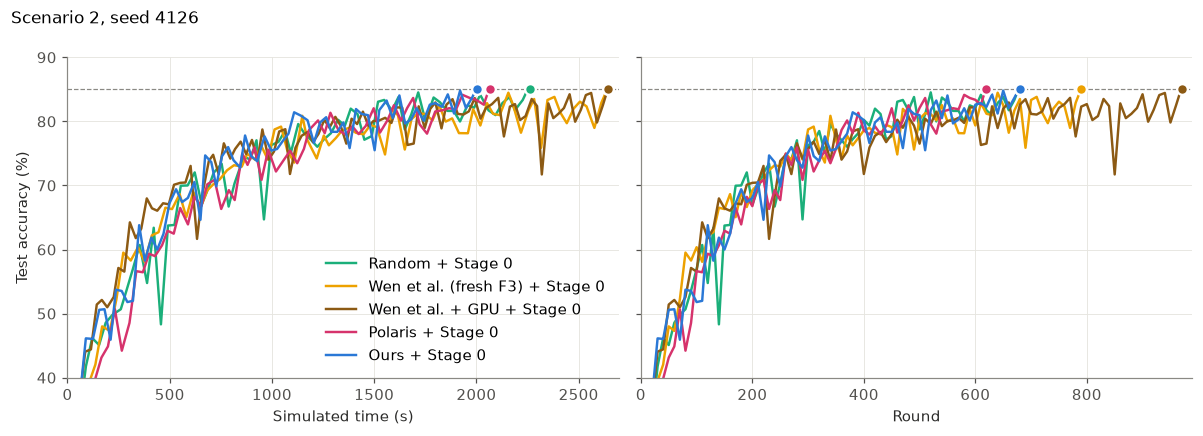

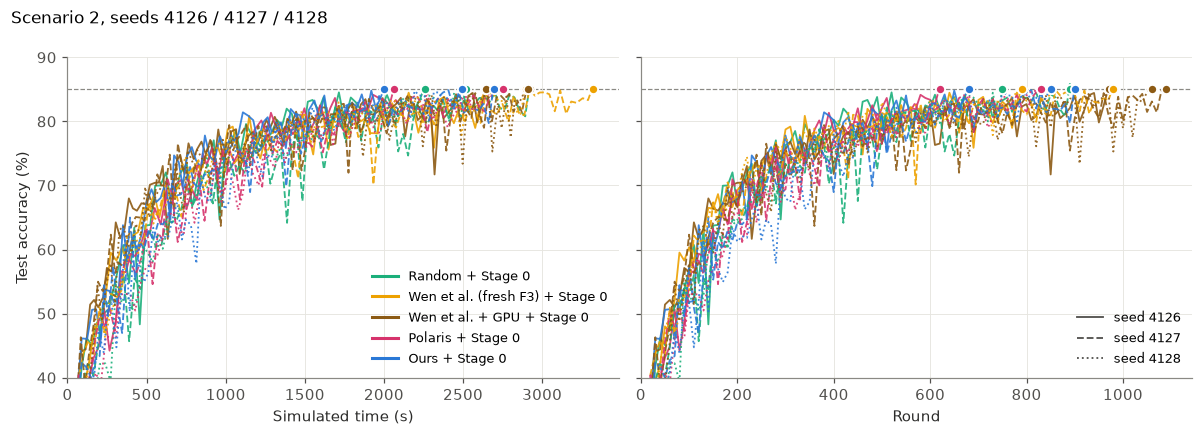

In [13]:
plot_curves(data_s2[SEED], METHODS_S2, f"Scenario 2, seed {SEED}", f"s2_{TAG}_training_curves_s{SEED}",
            FIG_DIR_S2)
plot_curves_seeds(data_s2, METHODS_S2, "Scenario 2, seeds 4126 / 4127 / 4128",
                  f"s2_{TAG}_training_curves_3seeds", FIG_DIR_S2)

## S2 Fig. 2 - Time to accuracy

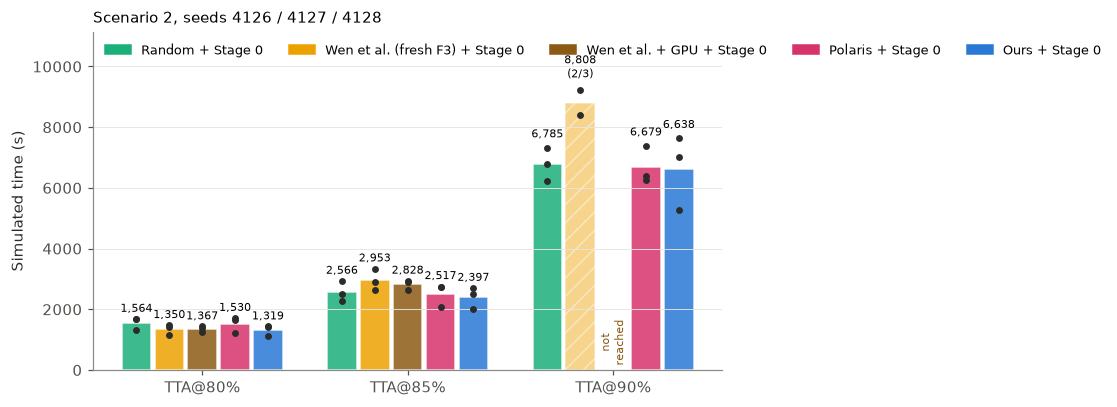

In [14]:
plot_tta(data_s2, METHODS_S2, "Scenario 2, seeds 4126 / 4127 / 4128", f"s2_{TAG}_tta_3seeds", FIG_DIR_S2)

## S2 Fig. 3 - Which vehicle types each method dispatches

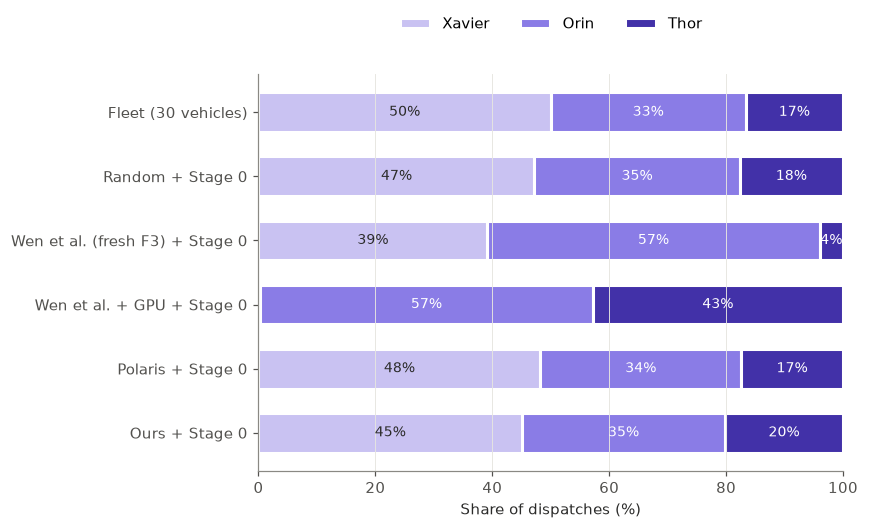

,xavier,orin,thor
Fleet (30 vehicles),50.0,33.3,16.7
Random + Stage 0,47.2,35.1,17.7
Wen et al. (fresh F3) + Stage 0,39.1,56.9,4.0
Wen et al. + GPU + Stage 0,0.3,56.8,42.8
Polaris + Stage 0,48.2,34.4,17.4
Ours + Stage 0,45.1,34.7,20.2


In [15]:
plot_tier_share(pool(data_s2), f"s2_{TAG}_tier_share_3seeds", FIG_DIR_S2)

## S2 Fig. 4 - Tier share per accuracy phase

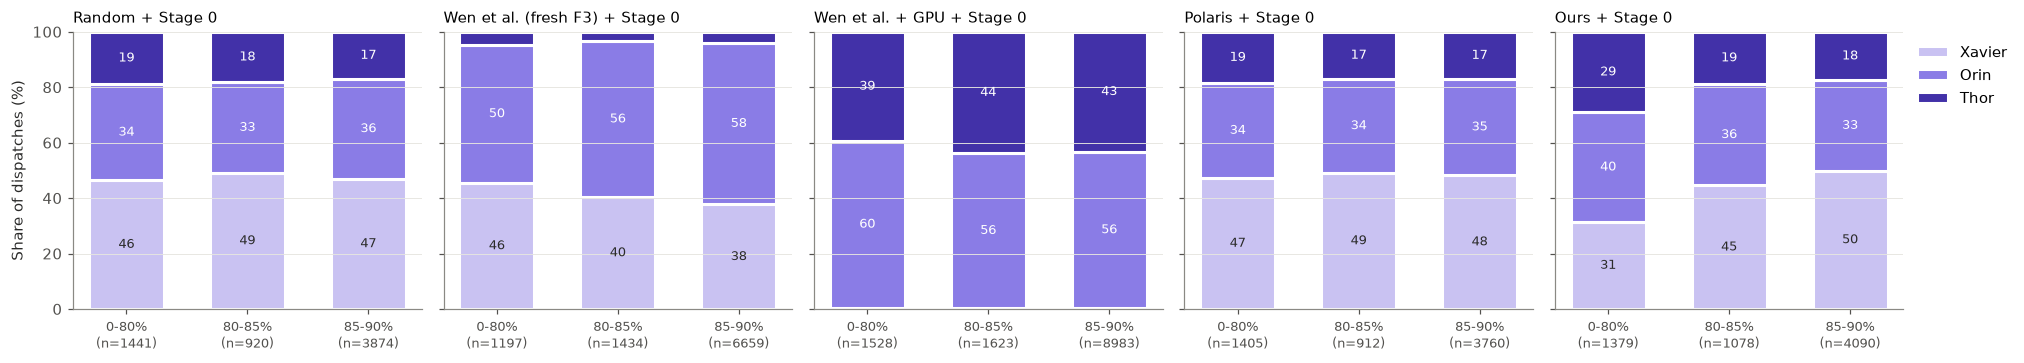

In [16]:
plot_tier_share_by_phase(pool(data_s2), f"s2_{TAG}_tier_share_by_phase_3seeds", FIG_DIR_S2)

## S2 Fig. 5 - Where the time goes

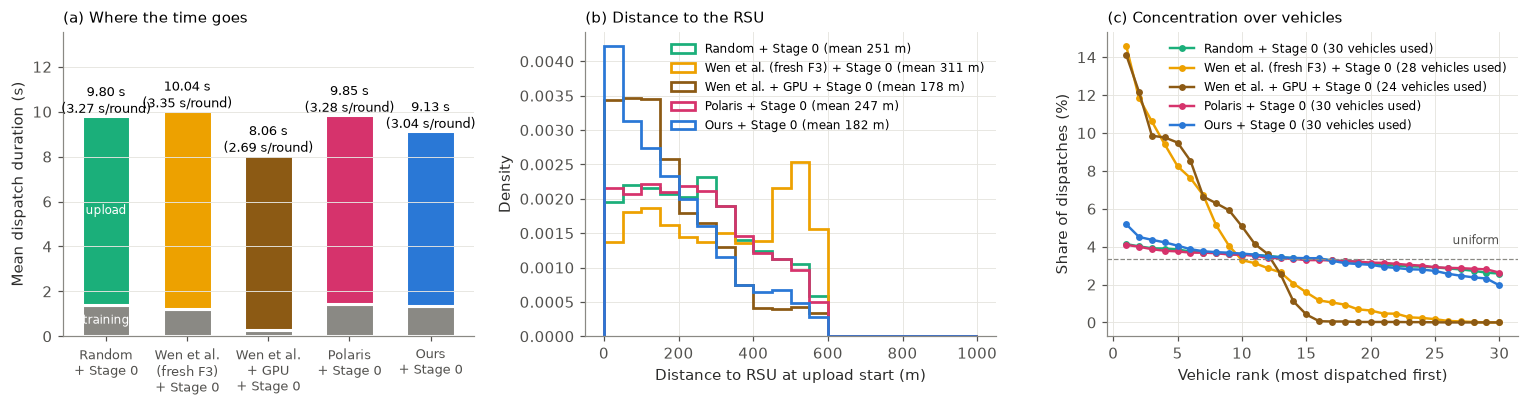

In [17]:
plot_why(pool(data_s2), METHODS_S2, f"s2_{TAG}_why_ours_faster_3seeds", FIG_DIR_S2)

## S2 Tables - numbers behind the figures

In [18]:
summary_table(data_s2[SEED])

,Random + Stage 0,Wen et al. (fresh F3) + Stage 0,Wen et al. + GPU + Stage 0,Polaris + Stage 0,Ours + Stage 0
TTA@80% (s),"1,324","1,149","1,256","1,225","1,109"
TTA@85% (s),"2,260","2,642","2,644","2,066","2,003"
TTA@90% (s),"6,242","8,387",not reached,"6,381","5,279"
rounds to 80%,400,340,460,370,380
rounds to 85%,680,790,970,620,680
rounds to 90%,"1,880","2,540",not reached,"1,930","1,720"
energy to 80% (kJ),25.7,19.1,13.0,24.5,20.3
energy to 85% (kJ),44.5,44.9,27.3,40.9,39.7
energy to 90% (kJ),121.6,138.9,not reached,128.8,112.1
max accuracy,0.9030,0.9000,0.8950,0.9017,0.9011


In [19]:
seeds_table(data_s2)

,Random + Stage 0,Wen et al. (fresh F3) + Stage 0,Wen et al. + GPU + Stage 0,Polaris + Stage 0,Ours + Stage 0
TTA@80% (s),"1,564 ± 208","1,350 ± 179","1,367 ± 99","1,530 ± 267","1,319 ± 184"
TTA@85% (s),"2,566 ± 334","2,953 ± 343","2,828 ± 159","2,517 ± 390","2,397 ± 355"
TTA@90% (s),"6,785 ± 543","8,808 ± 596 (2/3 reached)",not reached,"6,679 ± 618","6,638 ± 1,218"
rounds to 80%,470 ± 61,397 ± 51,503 ± 38,460 ± 79,453 ± 64
rounds to 85%,773 ± 107,873 ± 97,"1,040 ± 62",760 ± 121,810 ± 115
rounds to 90%,"2,047 ± 165","2,635 ± 134 (2/3 reached)",not reached,"1,997 ± 161","2,160 ± 392"
energy to 80% (kJ),31.0 ± 4.6,24.8 ± 4.9,14.0 ± 0.9,30.4 ± 5.1,23.8 ± 3.1
energy to 85% (kJ),51.4 ± 7.6,53.1 ± 7.4,28.9 ± 1.6,50.6 ± 8.5,46.9 ± 6.8
energy to 90% (kJ),134.9 ± 13.1,154.7 ± 22.3 (2/3 reached),not reached,133.6 ± 9.9,138.6 ± 24.0
max accuracy,0.9040 ± 0.0040,0.8996 ± 0.0015,0.8934 ± 0.0027,0.9009 ± 0.0008,0.9010 ± 0.0009


In [20]:
per_seed_table(data_s2)[["TTA@80% (s)", "TTA@85% (s)", "TTA@90% (s)", "rounds to 90%",
                          "energy to 90% (kJ)", "max accuracy", "s / round",
                          "distance to RSU at upload (m)", "Thor (%)",
                          "Gini of per-vehicle dispatches"]].round(3)

TTA@80% (s)  TTA@85% (s)  TTA@90% (s)  \
method                          seed                                          
Random + Stage 0                4126     1323.857     2260.025     6241.941   
                                4127     1692.860     2922.466     7327.791   
                                4128     1673.993     2515.496     6785.899   
Wen et al. (fresh F3) + Stage 0 4126     1148.652     2641.564     8386.600   
                                4127     1491.440     3320.984          NaN   
                                4128     1410.550     2897.741     9228.845   
Wen et al. + GPU + Stage 0      4126     1256.314     2644.499          NaN   
                                4127     1395.173     2925.566          NaN   
                                4128     1448.345     2912.801          NaN   
Polaris + Stage 0               4126     1225.318     2066.177     6381.227   
                                4127     1721.517     2734.084     7389.148   
                                4128     1643.642     2750.074     6266.401   
Ours + Stage 0                  4126     1108.520     2002.920     5279.010   
                                4127     1447.610     2693.538     7630.795   
                                4128     1401.711     2494.299     7005.402   

                                      rounds to 90%  energy to 90% (kJ)  \
method                          seed                                      
Random + Stage 0                4126         1880.0             121.635   
                                4127         2210.0             147.729   
                                4128         2050.0             135.338   
Wen et al. (fresh F3) + Stage 0 4126         2540.0             138.876   
                                4127            NaN                 NaN   
                                4128         2730.0             170.429   
Wen et al. + GPU + Stage 0      4126            NaN                 NaN   
                                4127            NaN                 NaN   
                                4128            NaN                 NaN   
Polaris + Stage 0               4126         1930.0             128.763   
                                4127         2180.0             144.910   
                                4128         1880.0             127.021   
Ours + Stage 0                  4126         1720.0             112.059   
                                4127         2470.0             158.729   
                                4128         2290.0             145.043   

                                      max accuracy  s / round  \
method                          seed                            
Random + Stage 0                4126         0.903      3.324   
                                4127         0.908      3.320   
                                4128         0.901      3.314   
Wen et al. (fresh F3) + Stage 0 4126         0.900      3.305   
                                4127         0.898      3.372   
                                4128         0.901      3.381   
Wen et al. + GPU + Stage 0      4126         0.895      2.732   
                                4127         0.890      2.680   
                                4128         0.895      2.744   
Polaris + Stage 0               4126         0.902      3.310   
                                4127         0.900      3.394   
                                4128         0.901      3.336   
Ours + Stage 0                  4126         0.901      3.073   
                                4127         0.900      3.092   
                                4128         0.902      3.062   

                                      distance to RSU at upload (m)  Thor (%)  \
method                          seed                                            
Random + Stage 0                4126                        254.400    18.920   
                                4127                        250.556  

## S2 Summary - one row per method (mean over seeds)

In [21]:
compact_table(data_s2)

,TTA@80% (s),TTA@85% (s),TTA@90% (s),energy to 90% (kJ),Xavier (%),Orin (%),Thor (%),s / round,distance to RSU at upload (m),Gini of per-vehicle dispatches,top-5 vehicles' share (%)
Random + Stage 0,"1,564 ± 208","2,566 ± 334","6,785 ± 543",134.9 ± 13.1,47.1 ± 1.5,35.1 ± 0.3,17.8 ± 1.2,3.32 ± 0.01,251 ± 3,0.073 ± 0.010,19.8 ± 0.5
Wen et al. (fresh F3) + Stage 0,"1,350 ± 179","2,953 ± 343","8,808 ± 596 (2/3 reached)",154.7 ± 22.3 (2/3 reached),39.2 ± 6.0,56.2 ± 9.2,4.6 ± 4.3,3.35 ± 0.04,310 ± 8,0.615 ± 0.019,54.7 ± 6.6
Wen et al. + GPU + Stage 0,"1,367 ± 99","2,828 ± 159",not reached,not reached,0.3 ± 0.0,56.9 ± 8.0,42.8 ± 8.0,2.72 ± 0.03,178 ± 13,0.663 ± 0.035,55.4 ± 6.2
Polaris + Stage 0,"1,530 ± 267","2,517 ± 390","6,679 ± 618",133.6 ± 9.9,48.2 ± 0.6,34.3 ± 0.3,17.4 ± 0.7,3.35 ± 0.04,247 ± 2,0.064 ± 0.011,19.5 ± 0.5
Ours + Stage 0,"1,319 ± 184","2,397 ± 355","6,638 ± 1,218",138.6 ± 24.0,45.1 ± 1.0,34.6 ± 1.6,20.2 ± 0.7,3.08 ± 0.02,181 ± 3,0.118 ± 0.005,22.3 ± 0.4


# Scenario 2 comparison - with vs without Stage 0 (3 seeds)

The five selectors in S2, each run once without and once with Stage 0: `S2_random` / `S2_random_s0`,
`S2_wen_fresh` / `S2_wen_fresh_s0`,
`S2_wen_fresh_gpu` / `S2_wen_fresh_gpu_s0`, `S2_polaris` / `S2_polaris_s0`, `S2_gpu` / `S2_gpu_stage0`.
Light colour = without Stage 0, dark colour = with Stage 0.

In [22]:
METHODS_CMP = {
    "Random": ("S2_random", "#8fd9bc"),
    "Random + Stage 0": ("S2_random_s0", "#1baf7a"),
    "Wen et al. (fresh F3)": ("S2_wen_fresh", "#f5cf7a"),
    "Wen et al. (fresh F3) + Stage 0": ("S2_wen_fresh_s0", "#eda100"),
    "Wen et al. + GPU": ("S2_wen_fresh_gpu", "#cfae80"),
    "Wen et al. + GPU + Stage 0": ("S2_wen_fresh_gpu_s0", "#8c5a14"),
    "Polaris": ("S2_polaris", "#f0a3bd"),
    "Polaris + Stage 0": ("S2_polaris_s0", "#d6336c"),
    "Ours": ("S2_gpu", "#9cc2ed"),
    "Ours + Stage 0": ("S2_gpu_stage0", "#2a78d6"),
}
data_cmp = load_all(METHODS_CMP)
compact_table(data_cmp)

,TTA@80% (s),TTA@85% (s),TTA@90% (s),energy to 90% (kJ),Xavier (%),Orin (%),Thor (%),s / round,distance to RSU at upload (m),Gini of per-vehicle dispatches,top-5 vehicles' share (%)
Random,"1,817 ± 140","3,116 ± 113","7,685 ± 627",150.9 ± 11.9,49.2 ± 1.1,33.5 ± 0.2,17.3 ± 1.0,4.41 ± 0.05,301 ± 5,0.056 ± 0.001,19.2 ± 0.3
Random + Stage 0,"1,564 ± 208","2,566 ± 334","6,785 ± 543",134.9 ± 13.1,47.1 ± 1.5,35.1 ± 0.3,17.8 ± 1.2,3.32 ± 0.01,251 ± 3,0.073 ± 0.010,19.8 ± 0.5
Wen et al. (fresh F3),"1,583 ± 392","3,126 ± 368","11,680 ± 1,939",198.9 ± 35.9,37.9 ± 6.9,57.9 ± 10.1,4.1 ± 4.3,3.50 ± 0.09,322 ± 10,0.639 ± 0.021,58.4 ± 7.4
Wen et al. (fresh F3) + Stage 0,"1,350 ± 179","2,953 ± 343","8,808 ± 596 (2/3 reached)",154.7 ± 22.3 (2/3 reached),39.2 ± 6.0,56.2 ± 9.2,4.6 ± 4.3,3.35 ± 0.04,310 ± 8,0.615 ± 0.019,54.7 ± 6.6
Wen et al. + GPU,"1,537 ± 206","3,533 ± 546",not reached,not reached,0.0 ± 0.0,52.9 ± 9.2,47.1 ± 9.2,3.11 ± 0.14,207 ± 23,0.717 ± 0.047,64.4 ± 7.8
Wen et al. + GPU + Stage 0,"1,367 ± 99","2,828 ± 159",not reached,not reached,0.3 ± 0.0,56.9 ± 8.0,42.8 ± 8.0,2.72 ± 0.03,178 ± 13,0.663 ± 0.035,55.4 ± 6.2
Polaris,"1,924 ± 142","3,162 ± 391","8,101 ± 141",159.9 ± 1.6,49.8 ± 0.4,33.0 ± 0.5,17.2 ± 0.6,4.43 ± 0.06,301 ± 4,0.054 ± 0.009,19.2 ± 0.6
Polaris + Stage 0,"1,530 ± 267","2,517 ± 390","6,679 ± 618",133.6 ± 9.9,48.2 ± 0.6,34.3 ± 0.3,17.4 ± 0.7,3.35 ± 0.04,247 ± 2,0.064 ± 0.011,19.5 ± 0.5
Ours,"1,416 ± 187","2,484 ± 471","6,869 ± 394",140.8 ± 8.8,45.2 ± 0.8,34.7 ± 0.9,20.0 ± 0.2,3.56 ± 0.03,214 ± 2,0.134 ± 0.014,23.1 ± 0.6
Ours + Stage 0,"1,319 ± 184","2,397 ± 355","6,638 ± 1,218",138.6 ± 24.0,45.1 ± 1.0,34.6 ± 1.6,20.2 ± 0.7,3.08 ± 0.02,181 ± 3,0.118 ± 0.005,22.3 ± 0.4


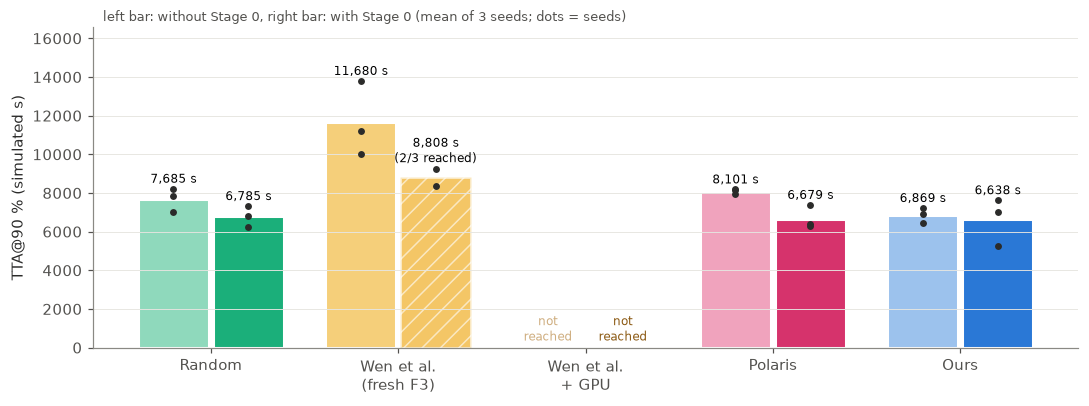

In [23]:
# TTA@90 % per selector, without vs with Stage 0: bar = mean over seeds that reached 90 %, dots = seeds
pairs = [("Random", "Random + Stage 0"),
         ("Wen et al. (fresh F3)", "Wen et al. (fresh F3) + Stage 0"),
         ("Wen et al. + GPU", "Wen et al. + GPU + Stage 0"),
         ("Polaris", "Polaris + Stage 0"),
         ("Ours", "Ours + Stage 0")]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(pairs))
top = 0
for k, off in [(0, -0.2), (1, 0.2)]:
    for xi, pair in zip(x, pairs):
        m = pair[k]
        ts = [d[m]["tta"][0.90][0] for d in data_cmp.values() if d[m]["tta"][0.90]]
        if not ts:   # no seed reached 90 %
            ax.text(xi + off, 150, "not\nreached", ha="center", va="bottom", fontsize=8,
                    color=METHODS_CMP[m][1])
            continue
        partial = len(ts) < len(SEEDS)
        ax.bar(xi + off, np.mean(ts), width=0.38, color=METHODS_CMP[m][1], edgecolor="white",
               linewidth=2, hatch="//" if partial else None, alpha=0.6 if partial else 1)
        ax.plot([xi + off] * len(ts), ts, "o", ms=3.5, color="#2b2b2a", zorder=5)
        lab = f"{np.mean(ts):,.0f} s" + (f"\n({len(ts)}/{len(SEEDS)} reached)" if partial else "")
        ax.text(xi + off, max(ts) + 150, lab, ha="center", va="bottom", fontsize=8)
        top = max(top, max(ts))
ax.set_xticks(x, [p[0].replace(" (", "\n(").replace(" + ", "\n+ ", 1) for p in pairs])
ax.set_ylabel("TTA@90 % (simulated s)")
ax.set_ylim(0, top * 1.2)
ax.grid(axis="x", visible=False)
ax.text(0.01, 1.02, "left bar: without Stage 0, right bar: with Stage 0 (mean of 3 seeds; dots = seeds)",
        transform=ax.transAxes, fontsize=8.5, color="#52514e")
fig.tight_layout()
save(fig, "s2_cmp_tta90_3seeds", FIG_DIR_S2)
plt.show()

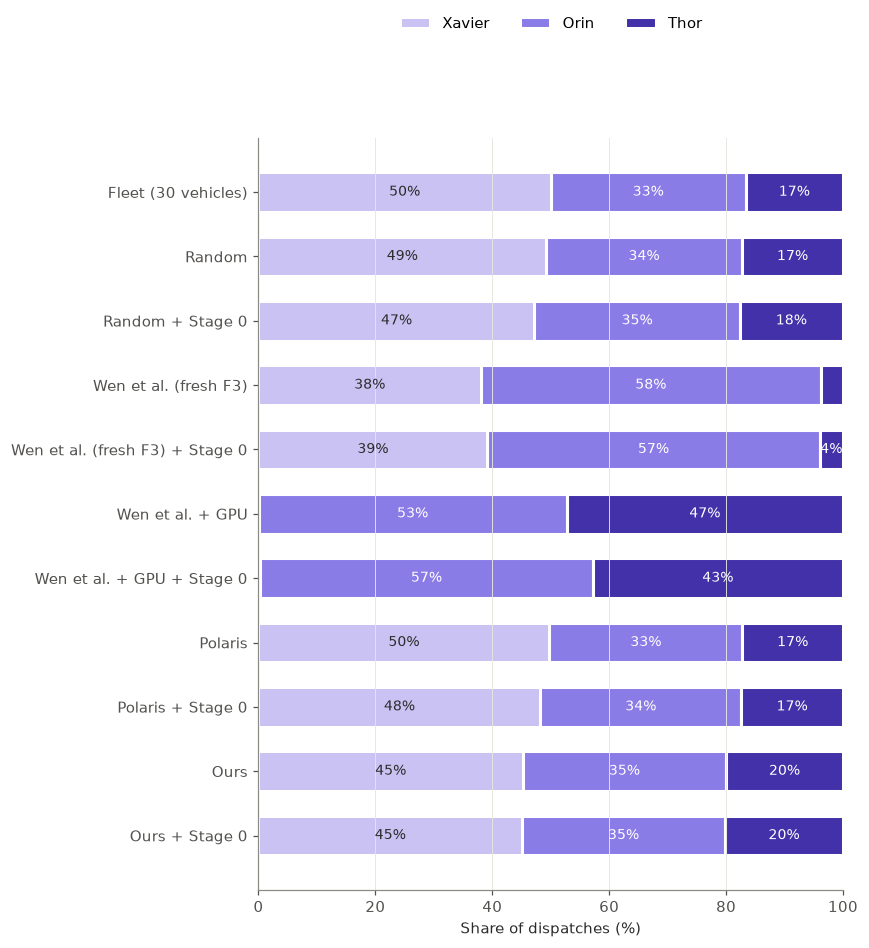

,xavier,orin,thor
Fleet (30 vehicles),50.0,33.3,16.7
Random,49.2,33.5,17.3
Random + Stage 0,47.2,35.1,17.7
Wen et al. (fresh F3),38.0,58.1,3.8
Wen et al. (fresh F3) + Stage 0,39.1,56.9,4.0
Wen et al. + GPU,0.0,52.7,47.3
Wen et al. + GPU + Stage 0,0.3,56.8,42.8
Polaris,49.8,33.0,17.2
Polaris + Stage 0,48.2,34.4,17.4
Ours,45.2,34.7,20.0


In [24]:
plot_tier_share(pool(data_cmp), "s2_cmp_tier_share_3seeds", FIG_DIR_S2)